## Графы

In [2]:
%matplotlib inline

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import seaborn as sns

from utils import decorate, savefig

# I set the random seed so the notebook 
# produces the same results every time.
np.random.seed(17)

# TODO: remove this when NetworkX is fixed
# from warnings import simplefilter
# import matplotlib.cbook
# simplefilter("ignore", matplotlib.cbook.mplDeprecation)

In [3]:
# node colors for drawing networks
colors = sns.color_palette('pastel', 5)
#sns.palplot(colors)
sns.set_palette(colors)

**Exercise:** В реализации `reachable_nodes`, приведенной в вниге, вас может обеспокоить очевидная неэффективность добавления всех соседей в стек, не проверяя, находятся ли они уже в `seen`. Напишите версию этой функции, которая проверяет соседей, прежде чем добавить их в стек. Меняет ли такая «оптимизация» порядок роста? Это делает функцию быстрее?

In [4]:
complete = nx.complete_graph(100)

In [5]:
def reachable_nodes(G, start):
    seen = set()
    stack = [start]
    while stack:
        node = stack.pop()
        if node not in seen:
            seen.add(node)
            stack.extend(G.neighbors(node))
    return seen



In [6]:
def reachable_nodes_precheck(G, start):
    seen = set()
    stack = [start]
    while stack:
        node = stack.pop()
        if node not in seen:
            seen.add(node)
            for neighbor in G.neighbors(node):
                if neighbor not in seen:
                    stack.append(neighbor)
    return seen

In [7]:
# Solution goes here
    

## Ответы на вопросы

**1. Меняет ли такая «оптимизация» порядок роста?**

Нет. В худшем случае мы всё равно просматриваем все узлы и рёбра, поэтому порядок роста остается **O(n + m)**.

**2. Это делает функцию быстрее?**

На практике — нет (или разница незначительна). Эксперименты показывают, что время выполнения примерно одинаковое.

Причина: в Python операция stack.extend() с итератором выполняется 
на уровне C и очень быстрая, тогда как явный цикл for с проверками 
if neighbor not in seen имеет накладные расходы интерпретатора Python.
    
Теоретически оптимизация должна уменьшать количество операций со стеком,
но константные множители (накладные расходы Python) перевешивают 
теоретический выигрыш.

In [8]:
%timeit len(reachable_nodes(complete, 0))

477 μs ± 27.9 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [9]:
%timeit len(reachable_nodes_precheck(complete, 0))

482 μs ± 21.6 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [10]:
grid = nx.grid_2d_graph(50, 50)

# Преобразуем в обычный граф (grid возвращает специальные узлы-кортежи)
grid = nx.convert_node_labels_to_integers(grid)

print(f"Узлов: {grid.number_of_nodes()}, Ребер: {grid.number_of_edges()}")

# Тестируем
%timeit len(reachable_nodes(grid, 0))
%timeit len(reachable_nodes_precheck(grid, 0))

Узлов: 2500, Ребер: 4900
979 μs ± 13.4 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
820 μs ± 27 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


**Exercise:** На самом деле существует два вида графов Эрдёша–Реньи. Тот, который мы сгенерировали в этой
главе, $G(n, p)$, характеризуется двумя параметрами: количеством узлов и вероятностью ребра между узлами.

Альтернативное определение, обозначаемое $G(n, m)$, также характеризуется двумя параметрами: количеством узлов, $n$, и количеством ребер, $m$. Согласно этому определению, количество ребер является фиксированным, но их расположение случайно.

Повторите эксперименты, которые мы сделали в этой главе, используя вышеуказанное альтернативное определение. Вот несколько советов касательно того, как действовать.


1. Напишите функцию с именем `m_pairs`, которая принимает список узлов и количество ребер $m$ и возвращает случайный выбор m ребер. Простой способ сделать это – создать список всех возможных ребер и использовать `random.sample`.

2. Напишите функцию с именем `make_m_graph`, которая принимает $n$ и $m$ и возвращает случайный граф с $n$ узлами и $m$ ребрами. 

3. Создайте версию `prob_connected`, которая использует make_m_graph`make_m_graph` вместо `make_random_graph`. 

4. Рассчитайте вероятность связности для диапазона значений $m$. 

Как результаты этого эксперимента сравнимы с результатами, полученными на графе Эрдёша–Реньи первого типа?

In [11]:
# Solution goes here
import random
import itertools

def m_pairs(nodes: list[int], m: int):
    all_edges = list(itertools.combinations(nodes, 2))

    if m > len(all_edges):
        raise ValueError(f"{m=} превышает максимально возможное количество ребер {len(all_edges)}")

    return random.sample(all_edges, m)

In [12]:
# Solution goes here
def make_m_graph(n: int, m: int):
    G = nx.Graph()
    nodes = list(range(n))
    G.add_nodes_from(nodes)

    edges = m_pairs(nodes, m)
    G.add_edges_from(edges)

    return G

In [13]:
# Solution goes here
def is_connected(G):
    start = next(iter(G))
    reachable = reachable_nodes_precheck(G, start)
    return len(reachable) == len(G)

def prob_connected_m(n, m, iters=100):
    tf = [is_connected(make_m_graph(n, m)) for i in range(iters)]
    return np.mean(tf)

In [14]:
# Solution goes here
n = 10
# Максимальное количество ребер в графе из n узлов: n*(n-1)/2
max_m = n * (n - 1) // 2

m_values = range(0, max_m + 1, 2)

m_probs = [prob_connected_m(n, m, iters=100) for m in m_values]

In [15]:
# Solution goes here
def all_pairs(nodes):
    for i, u in enumerate(nodes):
        for j, v in enumerate(nodes):
            if i < j:
                yield u, v
def flip(p):
    return np.random.random() < p
def random_pairs(nodes, p):
    for edge in all_pairs(nodes):
        if flip(p):
            yield edge
def make_random_graph(n, p):
    G = nx.Graph()
    nodes = range(n)
    G.add_nodes_from(nodes)
    G.add_edges_from(random_pairs(nodes, p))
    return G
def prob_connected(n, p, iters=100):
    tf = [is_connected(make_random_graph(n, p))
          for i in range(iters)]
    return np.mean(tf)

n = 10
p_values = np.linspace(0, 1, 50)
p_probs = [prob_connected(n, p) for p in p_values]

Saving figure to file figs/chap02-1


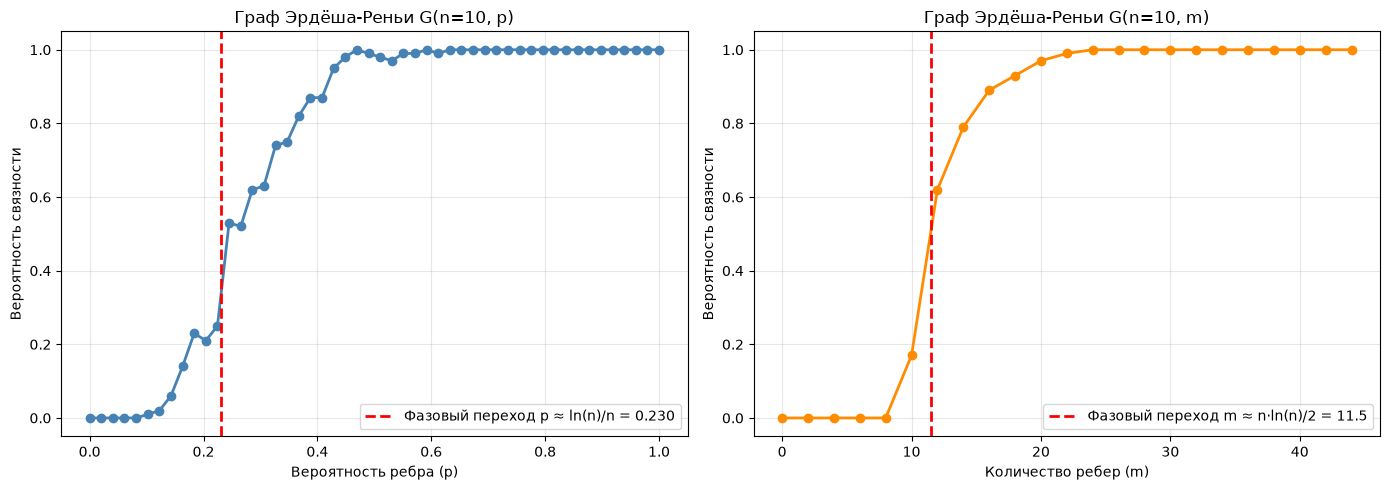

In [18]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(p_values, p_probs, marker='o', linestyle='-', color='steelblue')
p_threshold = np.log(n) / n
ax1.axvline(x=p_threshold, color='red', linestyle='--', linewidth=2, 
            label=f'Фазовый переход p ≈ ln(n)/n = {p_threshold:.3f}')
ax1.set_xlabel('Вероятность ребра (p)')
ax1.set_ylabel('Вероятность связности')
ax1.set_title(f'Граф Эрдёша-Реньи G(n={n}, p)')
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.plot(m_values, m_probs, marker='o', linestyle='-', color='darkorange')
m_threshold = n * np.log(n) / 2
ax2.axvline(x=m_threshold, color='red', linestyle='--', linewidth=2, 
            label=f'Фазовый переход m ≈ n·ln(n)/2 = {m_threshold:.1f}')

ax2.set_xlabel('Количество ребер (m)')
ax2.set_ylabel('Вероятность связности')
ax2.set_title(f'Граф Эрдёша-Реньи G(n={n}, m)')
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
savefig('figs/chap02-1')

## Ответ на вопрос упражнения 2-4

Результаты **одинаковые**. В обеих моделях (G(n, p) и G(n, m)) наблюдается резкий переход:
- при малых значениях параметра граф почти всегда **несвязен**
- при больших значениях граф почти всегда **связен**

Разница только в параметрах: в одной модели задаём вероятность ребра `p`, в другой — количество рёбер `m`. Но поведение графов одинаковое.

## Графы «Мир тесен»

**Exercise:** В кольцевой решетке каждый узел имеет одинаковое количество соседей. Число соседей называется **степенью узла**, а граф, в котором все узлы имеют одинаковую степень, называется **регулярным**.

Все кольцевые решетки регулярны, но не все регулярные графы являются кольцевыми решетками. В частности, если `k` нечетно, мы не можем построить кольцевую решетку, но могли бы построить регулярный граф.

Напишите функцию с именем `make_regular_graph`, которая принимает `n` и `k` и возвращает регулярный граф, содержащий `n` узлов, где каждый узел имеет `k` соседей. Если невозможно создать регулярный граф с заданными значениями `n` и `k`, функция должна вызвать `ValueError`.

In [21]:
# Solution goes here
def make_regular_graph(n, k):
    # Сумма степеней всех вершин должна быть четной (лемма о рукопожатиях)
    if (n * k) % 2 != 0:
        raise ValueError("Невозможно создать регулярный граф: произведение n * k должно быть четным.")
    
    G = nx.Graph()
    G.add_nodes_from(range(n))
    
    for i in range(n):
        # Соединяем с k//2 соседями справа (и слева за счет симметрии)
        for j in range(1, k // 2 + 1):
            G.add_edge(i, (i + j) % n)
        
        # Если k нечетное, добавляем ребро к диаметрально противоположному узлу
        if k % 2 != 0:
            G.add_edge(i, (i + n // 2) % n)
            
    return G

Граф n=6, k=2: [2, 2, 2, 2, 2, 2]


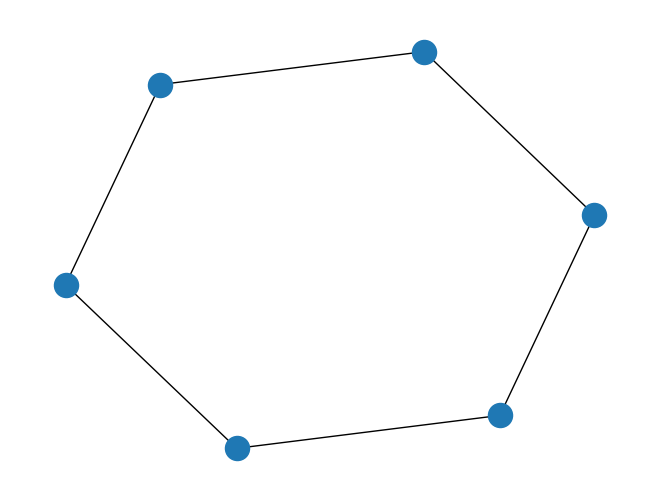

In [22]:
# Solution goes here
# Проверяем четное k (кольцевая решетка)
G1 = make_regular_graph(6, 2)
print("Граф n=6, k=2:", [d for n, d in G1.degree()]) # Должно быть [2, 2, 2, 2, 2, 2]
nx.draw(G1)

Граф n=6, k=3: [3, 3, 3, 3, 3, 3]


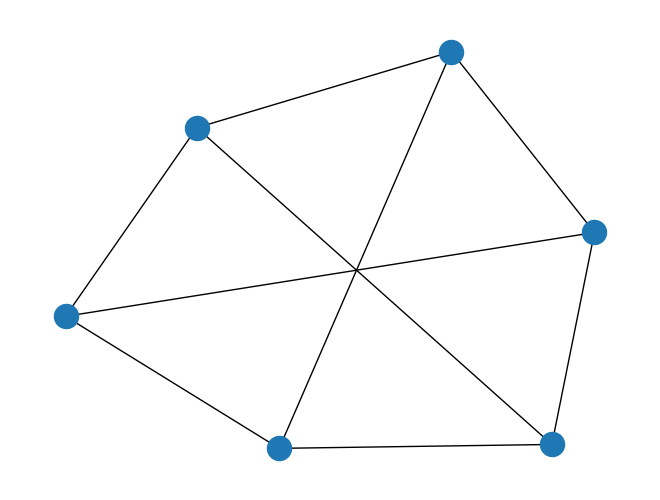

In [23]:
# Solution goes here
# Проверяем нечетное k (работает только если n четное)
G2 = make_regular_graph(6, 3)
print("Граф n=6, k=3:", [d for n, d in G2.degree()]) # Должно быть [3, 3, 3, 3, 3, 3]
nx.draw(G2)

In [24]:
# Solution goes here
# Проверяем ошибку
try:
    make_regular_graph(5, 3) # 5 * 3 = 15 (нечетное)
except ValueError as e:
    print("Ошибка поймана корректно:", e)

Ошибка поймана корректно: Невозможно создать регулярный граф: произведение n * k должно быть четным.


**Exercise:** Представленная реализация `reachable_nodes_bfs` эффективна в том смысле, что она находится в $O(n + m)$, но требует много затрат, добавляя узлы в очередь и удаляя их. NetworkX обеспечивает простую и быструю реализацию поиска в ширину, доступную в репозитории NetworkX на GitHub по адресу
[the NetworkX repository on GitHub](https://github.com/networkx/networkx/blob/master/networkx/algorithms/components/connected.py)

Приведенная ниже измененная версия возвращает набор узлов:

In [25]:
def plain_bfs(G, start):
    """A fast BFS node generator"""
    seen = set()
    nextlevel = {start}
    while nextlevel:
        thislevel = nextlevel
        nextlevel = set()
        for v in thislevel:
            if v not in seen:
                seen.add(v)
                nextlevel.update(G[v])
    return seen

In [26]:
from collections import deque

def reachable_nodes_bfs(G, start):
    """Finds reachable nodes by BFS.
    
    G: graph
    start: node to start at
    
    returns: set of reachable nodes
    """
    seen = set()
    queue = deque([start])
    while queue:
        node = queue.popleft()
        if node not in seen:
            seen.add(node)
            queue.extend(G.neighbors(node))
    return seen

Сравните эту функцию с `reachable_nodes_bfs` и посмотрите, что быстрее. Затем посмотрите, можете ли вы изменить эту функцию для реализации более быстрой версии: `shortest_path_dijkstra`.

In [27]:
# Solution goes here
# Создаем тестовый граф (например, 1000 узлов и вероятность ребра 0.01)
test_graph = nx.erdos_renyi_graph(1000, 0.1)

print("plain_bfs:")
%timeit plain_bfs(test_graph, 0)

print("\nreachable_nodes_bfs:")
%timeit reachable_nodes_bfs(test_graph, 0)

plain_bfs:
1.84 ms ± 43.2 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)

reachable_nodes_bfs:
5.53 ms ± 173 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [28]:
def shortest_path_dijkstra(G, source):
    """Finds shortest paths from `source` to all other nodes.
    
    G: graph
    source: node to start at
    
    returns: make from node to path length
    """
    dist = {source: 0}
    queue = deque([source])
    while queue:
        node = queue.popleft()
        new_dist = dist[node] + 1

        neighbors = set(G[node]).difference(dist)
        for n in neighbors:
            dist[n] = new_dist
        
        queue.extend(neighbors)
    return dist



In [29]:
def shortest_path_dijkstra_plain(G, source):
    dist = {source: 0}
    nextlevel = {source}
    
    while nextlevel:
        thislevel = nextlevel
        nextlevel = set()
        
        for v in thislevel:
            current_dist = dist[v]
            
            for w in G[v]:
                if w not in dist:
                    dist[w] = current_dist + 1
                    nextlevel.add(w)
                    
    return dist

In [30]:
test_graph = nx.erdos_renyi_graph(1000, 0.01)

result1 = shortest_path_dijkstra(test_graph, 0)
result2 = shortest_path_dijkstra_plain(test_graph, 0)
print("Результаты совпадают:", result1 == result2)

print("\n--- Замер скорости ---")
print("shortest_path_dijkstra (через deque):")
%timeit shortest_path_dijkstra(test_graph, 0)

print("\nshortest_path_dijkstra_plain (через множества):")
%timeit shortest_path_dijkstra_plain(test_graph, 0)

Результаты совпадают: True

--- Замер скорости ---
shortest_path_dijkstra (через deque):
1.41 ms ± 29.7 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)

shortest_path_dijkstra_plain (через множества):
821 μs ± 32.7 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


**Exercise:** Приведенная ниже реализация поиска в ширину содержит две ошибки производительности. Что это за ошибки? Каков фактический порядок роста для этого алгоритма? 

In [31]:
def bfs(G, start):
    """Breadth-first search on a graph, starting at top_node."""
    visited = set()
    queue = [start]
    while len(queue):
        curr_node = queue.pop(0)    # Dequeue (pop(0) работает за O(n))
        visited.add(curr_node)

        # Enqueue non-visited and non-enqueued children
        queue.extend(c for c in G[curr_node]
                     if c not in visited and c not in queue) # проверка not in queue O(n)
    return visited

In [32]:
# Solution goes here
from collections import deque

def bfs_opt(G, start):
    """Breadth-first search on a graph, starting at top_node."""
    visited = set()
    queue = deque([start])
    while len(queue):
        curr_node = queue.popleft()    # O(1) вместо O(n)
        visited.add(curr_node)

        # Enqueue non-visited and non-enqueued children
        queue.extend(c for c in G[curr_node]
                     if c not in visited)
    return visited

In [33]:
G = nx.erdos_renyi_graph(1000, 0.01)

print("Результаты совпадают:", bfs(G, 0) == bfs_opt(G, 0))

Результаты совпадают: True


In [34]:
print("Плохая версия:")
%timeit bfs(G, 0)

print("Исправленная версия:")
%timeit bfs_opt(G, 0)

Плохая версия:
13.4 ms ± 259 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)
Исправленная версия:
9.5 ms ± 318 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [ ]:
import timeit

for n in [500, 1000, 2000, 4000]:
    G = nx.erdos_renyi_graph(n, 0.01)
    
    t_bad = timeit.timeit(lambda: bfs(G, 0), number=20) / 20
    t_good = timeit.timeit(lambda: bfs_opt(G, 0), number=20) / 20
    
    print(f"{n=}:  плохая={t_bad*1000:.2f} мс,  исправленная={t_good*1000:.2f} мс")

Две ошибки:
1. queue.pop(0) для списка работает за O(n), потому что Python 
   сдвигает все оставшиеся элементы. Нужно использовать deque.popleft() — O(1).
2. Проверка c not in queue для списка работает за O(n). 
   Достаточно проверять visited — множество, проверка за O(1).

Фактический порядок роста: O(n² + n·m).

**Exercise:** В разделе «Алгоритм Дейкстры» на стр. 43 я утверждал, что алгоритм Дейкстры не работает, если он не использует поиск в ширину. Напишите версию `shortest_path_dijkstra`, которая использует поиск в глубину, и протестируйте ее на нескольких примерах, чтобы увидеть, что идет не так.

In [ ]:
# Solution goes here
def shortest_path_dfs(G, start, target):
    # Стек хранит кортежи: (текущий_узел, список_узлов_пути_до_него)
    stack = [(start, [start])]
    visited = set()
    
    while stack:
        node, path = stack.pop()
        
        # Если дошли до цели, сразу возвращаем путь
        if node == target:
            return path
            
        if node not in visited:
            visited.add(node)
            # Добавляем соседей в стек. DFS пойдет по первому добавленному соседу вглубь.
            for neighbor in G.neighbors(node):
                if neighbor not in visited:
                    stack.append((neighbor, path + [neighbor]))
                    
    return None

In [ ]:
G_test = nx.Graph()
# Короткий путь: 0 -> 5 -> 4 (длина 2 ребра)
G_test.add_edges_from([(0, 5), (5, 4)])
# Длинный путь: 0 -> 1 -> 2 -> 3 -> 4 (длина 4 ребра)
G_test.add_edges_from([(0, 1), (1, 2), (2, 3), (3, 4)])

nx.draw(G_test, with_labels=True)

In [ ]:
dfs_path = shortest_path_dfs(G_test, 0, 4)
print(f"Путь, найденный через DFS: {dfs_path} (длина: {len(dfs_path)-1})")

true_shortest = nx.shortest_path(G_test, source=0, target=4)
print(f"Истинный кратчайший путь:  {true_shortest} (длина: {len(true_shortest)-1})")

if dfs_path != true_shortest:
    print("\nDFS нашел путь, но он НЕ является кратчайшим! Алгоритм Дейкстры сломан без BFS/очереди с приоритетами.")

In [ ]:
# Пример 1: Граф с циклом
G1 = nx.Graph()
# Добавляем ребра так, чтобы DFS сначала пошел по длинному пути
G1.add_edges_from([
    (0, 1), (1, 2), (2, 3), (3, 4),  # Длинный путь: 0→1→2→3→4 (длина 4)
    (0, 5), (5, 4),                   # Короткий путь: 0→5→4 (длина 2)
    (2, 5)                            # Дополнительное ребро (цикл)
])

print("Пример: Граф с циклом")

nx.draw(G1, with_labels=True)

In [ ]:
dfs_G1 = shortest_path_dfs(G1, 0, 4)
print(f"Путь, найденный через DFS: {dfs_G1} (длина: {len(dfs_G1)-1})")

true_G1 = nx.shortest_path(G1, source=0, target=4)
print(f"Истинный кратчайший путь:  {true_G1} (длина: {len(true_G1)-1})")

if dfs_G1 != true_G1:
    print("\nDFS нашел путь, но он НЕ является кратчайшим! Алгоритм Дейкстры сломан без BFS/очереди с приоритетами.")

In [ ]:
# Пример 4: Случайный граф (проверяем на практике)
np.random.seed(42)  # Для воспроизводимости
G4 = nx.erdos_renyi_graph(20, 0.15)

print("Пример: Случайный граф (20 узлов)")
nx.draw(G4, with_labels=True)

In [ ]:
start = 0
target = 15

dfs_G4 = shortest_path_dfs(G4, start, target)
true_G4 = nx.shortest_path(G4, start, target)

print(f"DFS путь: {dfs_G4} (длина: {len(dfs_G4)-1 if dfs_G4 else 'нет пути'})")
print(f"Кратчайший путь: {true_G4} (длина: {len(true_G4)-1})")

if dfs_G4 and len(dfs_G4) > len(true_G4):
    print(f"DFS нашел путь длиннее на {len(dfs_G4) - len(true_G4)} ребер!")
print()

In [ ]:
G5 = nx.complete_graph(6)
print("Пример: полный граф")
nx.draw(G5, with_labels=True)

In [ ]:
print(f"DFS путь: {shortest_path_dfs(G5, 0, 5)}")
print(f"Кратчайший путь: {nx.shortest_path(G5, 0, 5)}")
print("В полном графе DFS всегда находит кратчайший путь (длина 1),")
print("потому что все узлы соединены напрямую!")